In [16]:
#librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.options.display.max_columns=None
import yaml

pd.options.display.max_rows=None

In [17]:
from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp

In [19]:
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

In [20]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

In [21]:
import importlib

In [22]:
from pathlib import Path

In [23]:
pwd

'f:\\06 proyectos git\\exp_modelo4\\notebooks'

In [24]:
#nombre de proyecto
nombre_exp='exp_modelo4' #colocar nombre de la carepta que contiene el proyecto

In [25]:
##ruta actual
ruta_actual = Path.cwd()
#Buscar la carpeta del proyecto en la ruta actual
partes = ruta_actual.parts
ruta_raiz = ruta_actual
for i, p in enumerate(partes):
    if p == nombre_exp:
        ruta_raiz = Path(*partes[:i + 1])
        break
ruta_raiz = str(ruta_raiz)

In [26]:
ruta_raiz

'f:\\06 proyectos git\\exp_modelo4'

In [27]:
#cargando metadata archivo configuracion .yaml
config_path = Path(ruta_raiz) / 'config' / 'model' / 'archivo_config.yaml'
with open(config_path, 'r', encoding='utf-8') as file:
    config = yaml.safe_load(file)


In [60]:
#recarga modulo cargado en memoria para no reiniciar kernel
importlib.reload(sys.modules['prep_EDA'])

<module 'prep_EDA' from 'f:\\06 proyectos git\\exp_modelo4\\src\\prep_EDA.py'>

In [61]:
###permite cargar modulos scripts.py
import sys
import os
dir=os.path.abspath(config['settings']['ruta_src'])
if dir not in sys.path:
    sys.path.append(dir)

In [62]:
from prep_EDA import validar_numerico #EDANumerico

In [31]:
#rutas data
path_data_pro=config['settings']['ruta_data_pro']
path_raiz=config['settings']['ruta_raiz']
path_data_raw=config['settings']['ruta_data_raw']
path_data_final=config['settings']['ruta_data_final']
path_models=config['settings']['ruta_models']

In [19]:
path_data_raw

'f:\\06 proyectos git\\exp_modelo4\\Data\\raw'

In [32]:
Path(path_data_raw) 

WindowsPath('f:/06 proyectos git/exp_modelo4/Data/raw')

In [ ]:
df = pd.read_csv(Path(path_data_raw) / "base_churn_telcov2.csv") #dataset varaibles nativas

## 1. Vamos a construir un dataset de modelamiento de churn con estas características:
1. Un registro único por CUSTOMER_ID y ventana temporal.
2. Variables numéricas agregadas mediante promedio, suma, máximo, mínimo y último valor.
3. Variables categóricas agregadas mediante moda y último valor.
4. Variables temporales de comportamiento: últimos 6 meses (6M), últimos 3 meses (3M) y último mes (UM).
5. El target se obtendrá exclusivamente del período siguiente a la ventana predictora.

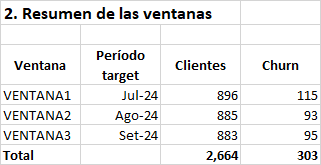

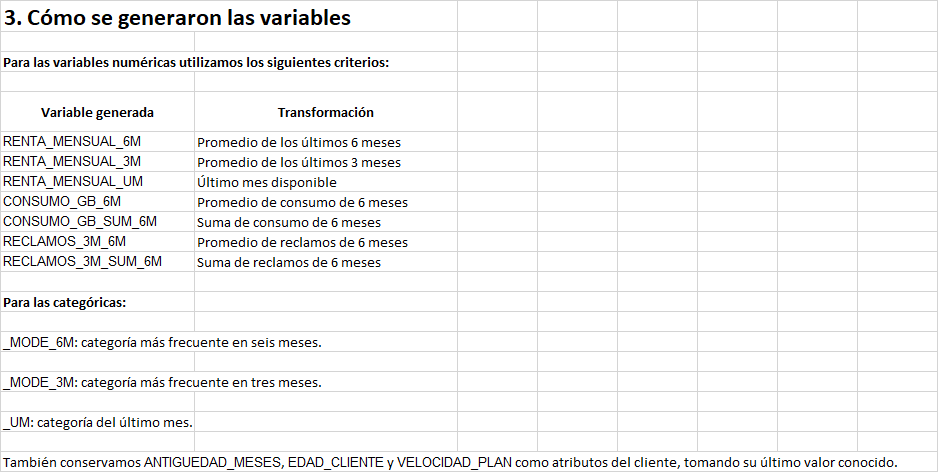

### codigo de agregacion

codigo_agregacion _forma _ventanas.txt (se encuentra en drive)

In [33]:
df = pd.read_csv(Path(path_data_raw) / "dataset_churn_ventanas.csv")

In [ ]:
#servidor
df = pd.read_csv(path_data_raw + "base_churn_telcov2.csv")

### exploracion previa

In [34]:
df.head(5)

,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET
0,CUST_000001,VENTANA1,0,129.0,72.0,50.0,6.479856,384.699198,0.833333,3.333333,1.166667,1.666667,1.833333,1.833333,8.710954,15.000000,13.500000,3.166667,1.833333,45.068107,37.833333,52.500000,2.0,20.666667,3691.652991,2.0,0.607967,1.000000,9.666667,11.139647,25.245184,57.613889,52.874262,1.0,5.711413,1.0,1.0,6.840057,0.709838,58.0,4.259030,11.0,5.0,11.0,6.0,12.0,81.0,90.0,11.0,19.0,20.0,7.0,10.0,6.715143,389.947847,1.000000,3.333333,1.000000,2.000000,1.333333,2.333333,8.198737,16.000000,14.333333,2.666667,2.666667,43.446478,50.000000,31.666667,2.0,29.000000,3893.858731,2.0,0.795065,0.666667,7.666667,15.601024,24.523643,29.979000,40.526860,1.0,5.910491,1.0,1.0,6.552893,1.049271,23.0,3.147813,4.0,3.0,8.0,2.0,6.0,43.0,48.0,7.0,8.0,10.0,3.0,6.0,9.463746,378.551997,2.0,5.0,1.0,2.0,3.0,4.0,8.234211,14.0,19.0,4.0,4.0,44.178550,43.0,21.0,2.0,30.0,NaN,2.0,0.854268,0.0,10.0,25.043955,30.472210,32.909588,53.395655,1.0,7.537784,1.0,1.0,10.661309,1.180396,Masivo,Masivo,Masivo,Fibra,Fibra,Fibra,Lima,Lima,Lima,M,M,M,Call Center,Call Center,Call Center,DIST_124,DI

In [35]:
df['VENTANA'].value_counts()

VENTANA
VENTANA1    896
VENTANA2    885
VENTANA3    883
Name: count, dtype: int64

### usaremos: 
* w1 para entrenar
* w2 para testear
* w3 como ott

In [36]:
# Filtrar el dataframe para incluir solo la ventana 1
df=df[df['VENTANA']=='VENTANA1']

In [37]:
TARGET = "TARGET_CHURN"
ID_COL = "CUSTOMER_ID"
num_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = df.select_dtypes(
    include=["object","category"]
).columns.tolist()

# excluir target y id

num_cols = [
    c for c in num_cols
    if c != TARGET
]

cat_cols = [
    c for c in cat_cols
    if c != ID_COL
]

In [38]:
#1. Cantidad de variables y filas
print("Filas :", len(df))
print("Columnas :", len(df.columns))

print("\nVariables Numéricas")
print(len(num_cols))

print("\nVariables Categóricas")
print(len(cat_cols))

Filas : 896
Columnas : 154

Variables Numéricas
130

Variables Categóricas
22


In [27]:
#2. Análisis de nulos
nulos = pd.DataFrame({

    "feature":df.columns,

    "nulos":
        df.isnull().sum(),

    "pct_nulos":
        round(
            100*df.isnull().mean(),
            2
        )

})

nulos.sort_values(
    "pct_nulos",
    ascending=False
)

,feature,nulos,pct_nulos
VELOCIDAD_REAL_UM,VELOCIDAD_REAL_UM,354,39.51
INGRESO_HOGAR_UM,INGRESO_HOGAR_UM,175,19.53
VELOCIDAD_REAL_3M,VELOCIDAD_REAL_3M,44,4.91
INGRESO_HOGAR_3M,INGRESO_HOGAR_3M,23,2.57
INGRESO_HOGAR_6M,INGRESO_HOGAR_6M,11,1.23
VELOCIDAD_REAL_6M,VELOCIDAD_REAL_6M,2,0.22
SATISFACCION_UM,SATISFACCION_UM,2,0.22
CUSTOMER_ID,CUSTOMER_ID,0,0.00
RENTA_MENSUAL_UM,RENTA_MENSUAL_UM,0,0.00
CONSUMO_GB_UM,CONSUMO_GB_UM,0,0.00


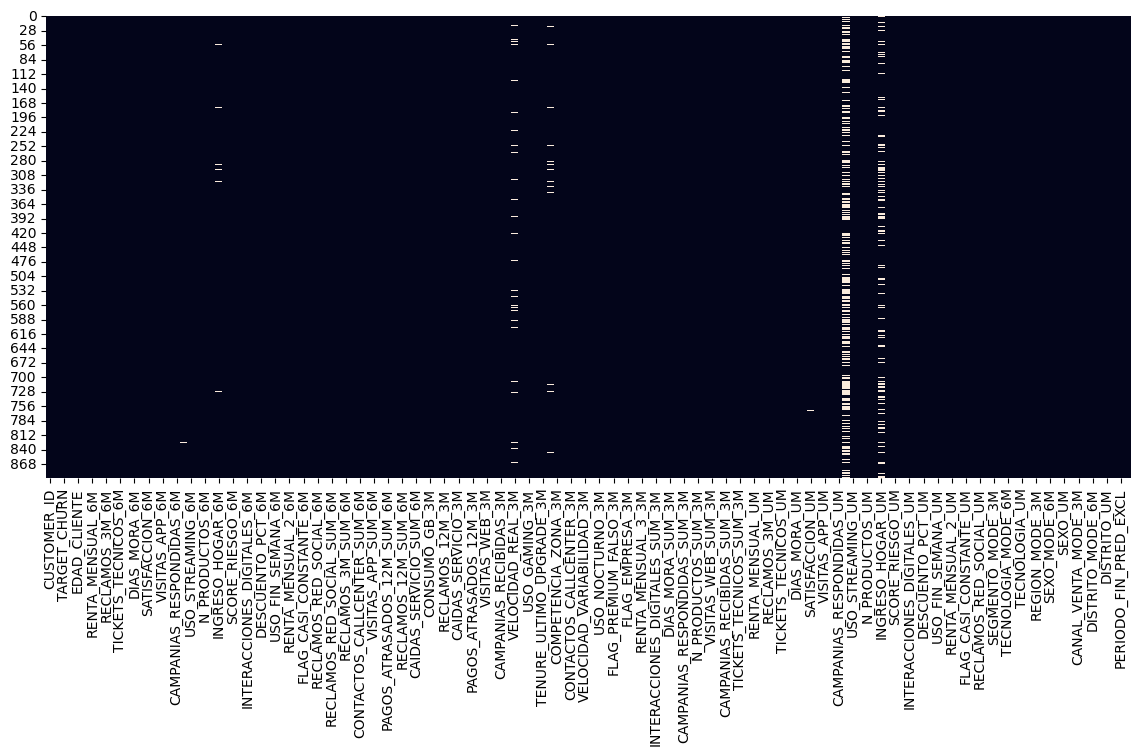

In [28]:
#Heatmap de nulos
plt.figure(figsize=(14,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.show()

### analizar Nulos segun su mecanismo (MCAR, MAR,MNAR)

In [29]:
def analizar_mecanismos_nulos(df, alpha=0.05, min_grupo=10):

    resultados = []
    resumen = []

    # Columnas que tienen valores nulos
    columnas_nulas = df.columns[df.isnull().any()].tolist()

    for target in columnas_nulas:

        # Indicador de ausencia: 1 = nulo, 0 = presente
        indicador = df[target].isnull()

        nulos = indicador.sum()
        porcentaje = indicador.mean() * 100

        pruebas = []

        # Analizar las demás variables
        for variable in df.columns:

            if variable == target:
                continue

            # Registros donde la variable predictora está disponible
            datos = pd.DataFrame({
                "x": df[variable],
                "missing": indicador
            }).dropna(subset=["x"])

            grupo_nulo = datos.loc[
                datos["missing"], "x"
            ]

            grupo_presente = datos.loc[
                ~datos["missing"], "x"
            ]

            if (len(grupo_nulo) < min_grupo or
                len(grupo_presente) < min_grupo):
                continue

            try:

                # Variables numéricas
                if pd.api.types.is_numeric_dtype(datos["x"]):

                    if datos["x"].nunique() < 2:
                        continue

                    estadistico, pvalor = mannwhitneyu(
                        grupo_nulo,
                        grupo_presente,
                        alternative="two-sided"
                    )

                    tipo_prueba = "Mann-Whitney U"

                # Variables categóricas
                else:

                    tabla = pd.crosstab(
                        datos["x"],
                        datos["missing"]
                    )

                    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
                        continue

                    chi2, pvalor, _, _ = chi2_contingency(
                        tabla
                    )

                    tipo_prueba = "Chi-cuadrado"

                pruebas.append({
                    "variable_nula": target,
                    "variable_explicativa": variable,
                    "tipo_prueba": tipo_prueba,
                    "pvalor": pvalor,
                    "n_muestra": len(datos)
                })

            except (ValueError, TypeError):
                continue

        # Corrección por múltiples comparaciones
        if pruebas:

            pvalores = [p["pvalor"] for p in pruebas]

            _, p_ajustados, _, _ = multipletests(
                pvalores,
                alpha=alpha,
                method="fdr_bh"
            )

            for prueba, p_ajustado in zip(
                pruebas, p_ajustados
            ):

                prueba["pvalor_ajustado"] = p_ajustado

                prueba["asociacion"] = (
                    "Significativa"
                    if p_ajustado < alpha
                    else "No significativa"
                )

                resultados.append(prueba)

            significativas = sum(
                p < alpha for p in p_ajustados
            )

        else:
            significativas = 0

        # Diagnóstico orientativo
        if significativas > 0:

            diagnostico = "MCAR rechazada - compatible con MAR"

        else:

            diagnostico = (
                "Sin evidencia contra MCAR - no concluyente"
            )

        resumen.append({
            "variable": target,
            "nulos": nulos,
            "porcentaje_nulos": round(porcentaje, 2),
            "variables_evaluadas": len(pruebas),
            "asociaciones_significativas": significativas,
            "diagnostico": diagnostico
        })

    df_resumen = pd.DataFrame(resumen)

    df_detalle = pd.DataFrame(resultados)

    if not df_detalle.empty:
        df_detalle = df_detalle.sort_values(
            ["variable_nula", "pvalor_ajustado"]
        )

    return df_resumen, df_detalle


In [30]:
df_resumen, df_detalle = analizar_mecanismos_nulos(df)

display(df_resumen)

,variable,nulos,porcentaje_nulos,variables_evaluadas,asociaciones_significativas,diagnostico
0,VELOCIDAD_REAL_6M,2,0.22,0,0,Sin evidencia contra MCAR - no concluyente
1,INGRESO_HOGAR_6M,11,1.23,142,0,Sin evidencia contra MCAR - no concluyente
2,VELOCIDAD_REAL_3M,44,4.91,145,0,Sin evidencia contra MCAR - no concluyente
3,INGRESO_HOGAR_3M,23,2.57,145,1,MCAR rechazada - compatible con MAR
4,SATISFACCION_UM,2,0.22,0,0,Sin evidencia contra MCAR - no concluyente
5,VELOCIDAD_REAL_UM,354,39.51,146,0,Sin evidencia contra MCAR - no concluyente
6,INGRESO_HOGAR_UM,175,19.53,146,2,MCAR rechazada - compatible con MAR


### tratamiento de nulos

### Estrategia recomendada por variable

Priorizando conservación de información y desempeño predictivo para tu modelo de churn.


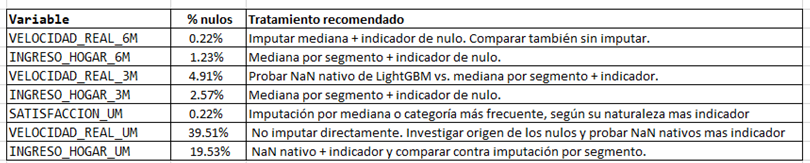

## deteccion de anomalias

es importante es entender que cada técnica observa los datos desde una perspectiva diferente:
- IQR: detecta valores extremos comparándolos con los cuartiles.
- MAD: detecta valores alejados de la mediana utilizando una medida robusta de dispersión.
- Isolation Forest: detecta registros que presentan combinaciones inusuales de variables.

El resultado final no es solamente identificar qué valores son extraños, sino también identificar qué clientes presentan comportamientos atípicos.

In [31]:
def detectar_anomalias(
    df,
    contamination=0.02,
    iqr_factor=1.5,
    mad_threshold=3.5,
    random_state=42,
    excluir=None
):

    excluir = set(excluir or [])

    # Detectar identificadores por nombre
    patrones_id = ("ID", "CODIGO", "COD_", "DNI")

    excluir.update([ # evitando que los identificadores participen en la detección.
        c for c in df.columns
        if any(p in c.upper() for p in patrones_id)
    ])

    # Columnas numéricas
    numericas = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    columnas = [
        c for c in numericas
        if c not in excluir
        and df[c].nunique(dropna=True) > 10 #Esto significa que solo analizas columnas numéricas que tengan más de 10 valores distintos.
    ]

    if not columnas:
        raise ValueError("No hay variables numéricas aptas para analizar.")

    # Copia de trabajo
    datos = df[columnas].replace(
        [np.inf, -np.inf], np.nan
    )

    resumen = []
    flags = pd.DataFrame(index=df.index)

    # ==========================================
    # 1. ANÁLISIS UNIVARIADO: IQR Y MAD
    # ==========================================
    # La palabra univariado significa que analizas una variable a la vez, sin considerar las demás.
    # Por ejemplo, puedes analizar si la velocidad de un cliente es inusualmente alta o baja sin importar cuánto paga o cuánto consume.
    for col in columnas:

        x = datos[col].dropna()

        if len(x) < 10:
            continue

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)

        iqr = q3 - q1

        limite_inf = q1 - iqr_factor * iqr
        limite_sup = q3 + iqr_factor * iqr

        flag_iqr = ( #resultado de si es o no un outlier segun el metodo IQR, es decir si esta fuera de los limites inferior y superior
            (datos[col] < limite_inf) |
            (datos[col] > limite_sup)
        ).fillna(False)
        # Nota:  IQR identifica valores estadísticamente extremos, no necesariamente errores. Un cliente con 200 Mbps 
        # podría tener perfectamente ese servicio contratado.

        # MAD: desviación absoluta mediana
        # Esta técnica también identifica valores extremos, pero utiliza como referencia la mediana.
        mediana = x.median()

        mad = np.median(
            np.abs(x - mediana)
        )

        if mad > 0:

            robust_z = (
                0.67448975 *
                (datos[col] - mediana) / mad
            )

            flag_mad = (
                robust_z.abs() > mad_threshold
            ).fillna(False)

        else:
            robust_z = pd.Series(
                np.nan, index=df.index
            )

            flag_mad = pd.Series(
                False, index=df.index
            )

        flags[f"{col}_IQR"] = flag_iqr
        flags[f"{col}_MAD"] = flag_mad

        resumen.append({
            "variable": col,
            "n_validos": len(x),
            "n_nulos": df[col].isna().sum(),
            "mediana": mediana,
            "Q1": q1,
            "Q3": q3,
            "limite_inferior": limite_inf,
            "limite_superior": limite_sup,
            "outliers_IQR": int(flag_iqr.sum()),
            "porcentaje_IQR": round(
                flag_iqr.mean() * 100, 2
            ),
            "outliers_MAD": int(flag_mad.sum()),
            "porcentaje_MAD": round(
                flag_mad.mean() * 100, 2
            )
        })

    resumen_anomalias = pd.DataFrame(resumen)
    
    # ¿Por qué utilizar IQR y MAD simultáneamente?
    # Porque no identifican exactamente los mismos valores. Sus criterios de detección son diferentes.
    # IQR trabaja con los cuartiles y MAD trabaja con la dispersión absoluta respecto a la mediana.
    # Incluso pueden marcar un valor de forma distinta.

    # ==========================================
    # 2. ANÁLISIS MULTIVARIADO: ISOLATION FOREST
    # ==========================================
    # independiente mente cada una de sus features podria estar dentro de los limites de IQR y MAD, pero en conjunto pueden ser anómalas.
    columnas_if = [
        c for c in columnas
        if datos[c].nunique(dropna=True) > 2
    ]
    
    #preproceso de datos para el algoritmo Isolation Forest
    if len(columnas_if) >= 2: # Seleccionas variables con más de dos valores distintos.
        # Construyes la matriz que utilizará Isolation Forest.
        matriz = datos[columnas_if].copy()

        # Imputación temporal para el algoritmo
        matriz = SimpleImputer(
            strategy="median"  # Aquí reemplazas temporalmente los valores faltantes con la mediana de cada variable.
        ).fit_transform(matriz)
        # esta imputación es exclusivamente para que Isolation Forest pueda procesar la matriz. No modifica tu DataFrame original.
        # Sin embargo, para tu análisis de nulos, hay una consideración: un valor imputado puede influir en el resultado del detector. 
        # Por eso conviene conservar indicadores de ausencia y evaluar qué ocurre con los registros que tienen muchos nulos.
        
        # Escalamiento robusto
        # Este escalador transforma las variables considerando su mediana y su rango intercuartílico.
        # Esto ayuda a que las diferencias de escala no dominen la representación de los datos.
        
        matriz = RobustScaler().fit_transform(matriz)
        
        # Entrenamiento de Isolation Forest
        modelo = IsolationForest( 
            n_estimators=200, #Construye 200 árboles de aislamiento.
            contamination=contamination, # Asume aproximadamente 2% de anomalías para definir el umbral de clasificación.
            random_state=random_state,
            n_jobs=-1
        )
        # Esto no significa que el algoritmo haya descubierto que el 2% de tus clientes son anómalos.
        # Significa que estás indicando al modelo que utilice un umbral asociado a una proporción esperada de anomalías del 2%.
        
        predicciones = modelo.fit_predict(matriz)
        # El método fit_predict ajusta el modelo a los datos y devuelve una predicción para cada registro: -1 indica anomalía y 1 indica normalidad.
        flags["ISOLATION_FOREST"] = (
            predicciones == -1
        )

        scores = modelo.decision_function(matriz)
        # Aquí obtienes una puntuación:
        # Valores negativos: registros clasificados como anomalías.
        #Valores positivos: registros clasificados como normales.
        #Cuanto más negativo sea el valor, más anómalo es el registro respecto al umbral aprendido.

        flags["IF_SCORE"] = scores

    else:

        flags["ISOLATION_FOREST"] = False

    # ==========================================
    # 3. INDICADORES GENERALES POR REGISTRO
    # ==========================================

    columnas_iqr = [
        c for c in flags.columns
        if c.endswith("_IQR")
    ]

    columnas_mad = [
        c for c in flags.columns
        if c.endswith("_MAD")
    ]

    flags["TOTAL_OUTLIERS_IQR"] = ( # Esto cuenta cuántas variables fueron marcadas por IQR para cada cliente.
        flags[columnas_iqr].sum(axis=1)
        if columnas_iqr else 0
    )

    flags["TOTAL_OUTLIERS_MAD"] = ( #total para cada cliente de variables marcadas por MAD
        flags[columnas_mad].sum(axis=1)
        if columnas_mad else 0
    )

    flags["ANOMALIA_IF"] = ( # indica si el registro fue marcado como anómalo por Isolation Forest
        flags["ISOLATION_FOREST"].astype(int)
    )

    # Clasificación orientativa
    flags["NIVEL_ANOMALIA"] = np.select(
        [
            (flags["TOTAL_OUTLIERS_IQR"] +
             flags["TOTAL_OUTLIERS_MAD"] >= 3) |
            (flags["ANOMALIA_IF"] == 1),

            (flags["TOTAL_OUTLIERS_IQR"] +
             flags["TOTAL_OUTLIERS_MAD"] >= 1)
        ],
        [
            "Revisar",
            "Moderado"
        ],
        default="Sin alerta"
    )

    # ==========================================
    # 4. DETECTAR INFINITOS
    # ==========================================
    # Los valores infinitos pueden surgir de divisiones por cero o de operaciones matemáticas extremas.
    # aqui buscamos el numero de valores infinitos por variable numerica, para luego poder analizarlos y decidir que hacer con ellos
    infinitos = pd.DataFrame(
        np.isinf(df[numericas]),
        columns=numericas,
        index=df.index
    )

    resumen_infinitos = infinitos.sum().rename(
        "valores_infinitos"
    )

    # ==========================================
    # 5. RESULTADOS
    # ==========================================
    # Tu función devuelve cuatro objetos:
    #resumen_anomalias	Resumen por variable: límites, cantidad y porcentaje de outliers.
    #df_anomalias;	Clientes que presentan alguna alerta.
    #df_scoring;	DataFrame original más los indicadores de anomalías.
    # resumen_infinitos;	Cantidad de infinitos por variable.

    df_scoring = df.join(flags)

    df_anomalias = df_scoring[
        (df_scoring["NIVEL_ANOMALIA"] != "Sin alerta")
    ].copy()

    return (
        resumen_anomalias.sort_values(
            "porcentaje_IQR",
            ascending=False
        ),
        df_anomalias,
        df_scoring,
        resumen_infinitos
    )


In [32]:
resumen_anomalias, df_anomalias, df_scoring, resumen_infinitos = (
    detectar_anomalias(
        df,
        contamination=0.02,
        excluir=["CUSTOMER_ID"]
    )
)

In [33]:
#visualizar
display(resumen_anomalias)

print("Registros anómalos:", len(df_anomalias))

display(df_anomalias.head(20))

print("Valores infinitos:")
display(resumen_infinitos[resumen_infinitos > 0])

,variable,n_validos,n_nulos,mediana,Q1,Q3,limite_inferior,limite_superior,outliers_IQR,porcentaje_IQR,outliers_MAD,porcentaje_MAD
71,VISITAS_APP_UM,896,0,11.000000,9.000000,14.000000,1.500000e+00,21.500000,53,5.92,0,0.00
43,VISITAS_APP_3M,896,0,11.666667,10.333333,13.333333,5.833333e+00,17.833333,52,5.80,48,5.36
61,VISITAS_APP_SUM_3M,896,0,35.000000,31.000000,40.000000,1.750000e+01,53.500000,52,5.80,48,5.36
66,RENTA_MENSUAL_UM,896,0,30.433486,14.951857,49.795195,-3.731315e+01,102.060204,51,5.69,43,4.80
81,RENTA_MENSUAL_2_UM,896,0,31.387003,15.734598,50.625956,-3.660244e+01,102.962993,51,5.69,43,4.80
11,VISITAS_APP_6M,896,0,11.833333,10.833333,12.833333,7.833333e+00,15.833333,51,5.69,47,5.25
82,RENTA_MENSUAL_3_UM,896,0,29.529122,14.446010,48.915839,-3.725873e+01,100.620582,50,5.58,43,4.80
30,VISITAS_APP_SUM_6M,896,0,71.000000,65.000000,77.000000,4.700000e+01,95.000000,50,5.58,47,5.25
13,USO_GAMING_6M,896,0,48.333333,40.500000,56.666667,1.625000e+01,80.916667,49,5.47,47,5.25
3,CONSUMO_GB_6M,896,0,268.489849,203.760811,352.044389,-1.866456e+01,574.469755,47,5.25,41,4.58


Registros anómalos: 342


,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET,ANTIGUEDAD_MESES_IQR,ANTIGUEDAD_MESES_MAD,EDAD_CLIENTE_IQR,EDAD_CLIENTE_MAD,RENTA_MENSUAL_6M_IQR,RENTA_MENSUAL_6M_MAD,CONSUMO_GB_6M_IQR,CONSUMO_GB_6M_MAD,RECLAMOS_3M_6M_IQR,RECLAMOS_3M_6M_MAD,RECLAMOS_12M_6M_IQR,RECLAMOS_12M_6M_MAD,TICKETS_TECNICOS_6M_IQR,TICKETS_TECNICOS_6M_MAD,DIAS_MORA_6M_IQR,DIAS_MORA_6M_MAD,PAGOS_ATRASADOS_12M_6M_IQR,PAGOS_ATRASADOS_12M_6M_MAD,SATISFACCION_6M_IQR,SATISFACCION_6M_MAD,VISITAS_WEB_6M_IQR,VISITAS_WEB_6M_MAD,VISITAS_APP_6M_IQR,VISITAS_APP_6M_MAD,USO_STREAMING_6M_IQR,USO_STREAMING_6M_MAD,USO_GAMING_6M_IQR,USO_GAMING_6M_MAD,TENURE_ULTIMO_UPGRADE_6M_IQR,TENURE_ULTIMO_UPGRADE_6M_MAD,INGRESO_HOGAR_6M_IQR,INGRESO_HOGAR_6M_MAD,SCORE_RIESGO_6M_IQR,SCORE_RIESGO_6M_MAD,CONTACTOS_CALLCENTER_6M_IQR,CONTACTOS_CALLCENTER_6M_MAD,INTERACCIONES_DIGITALES_6M_IQR,INTERACCIONES_DIGITALES_6M_MAD,DESCUENTO_PCT_6M_IQR,DESCUENTO_PCT_6M_MAD,USO_NOCTURNO_6M_IQR,USO_NOCTURNO_6M_MAD,USO_FIN_SEMANA_6M_IQR,USO_FIN_SEMANA_6M_MAD,RENTA_MENSUAL_2_6M_IQR,RENTA_MENSUAL_2_6M_MAD,RENTA_MENSUAL_3_6M_IQR,RENTA_MENSUAL_3_6M_MAD,RECLAMOS_RED_SOCIAL_6M_IQR

Valores infinitos:


Series([], Name: valores_infinitos, dtype: int64)

### ¿Cómo utilizaría estas anomalías en el proyecto de churn?

No utilizaría el resultado para eliminar automáticamente clientes. Lo utilizaría para entender comportamientos atípicos y mejorar la calidad del modelo.

### Asimetria

In [34]:
def data_asimetria(df):
    def classificar_asimetria(valor_skew,umbral=1):
        if valor_skew > umbral:
            return " Asimetria positiva extrema"
        elif valor_skew <-umbral:
            return "Asimetria negativa extrema"
        else:
            return " Tiende Simetrica"
       
    resultados=[]
    for col in df.select_dtypes(include=[np.number]).columns:
        skew_val=df[col].skew()
        clasificacion=classificar_asimetria(skew_val,umbral=1)
        resultados.append([col,skew_val,clasificacion])
       
    #df final
    df_asimetria=pd.DataFrame(resultados,columns=['Variable','Skewness','Clasificacion'])
   
    return df_asimetria

In [35]:
df_asimetria=data_asimetria(df)

In [36]:
df_asimetria

,Variable,Skewness,Clasificacion
0,TARGET_CHURN,2.226014,Asimetria positiva extrema
1,ANTIGUEDAD_MESES,-0.022837,Tiende Simetrica
2,EDAD_CLIENTE,0.454836,Tiende Simetrica
3,VELOCIDAD_PLAN,2.215907,Asimetria positiva extrema
4,RENTA_MENSUAL_6M,2.222741,Asimetria positiva extrema
5,CONSUMO_GB_6M,3.706238,Asimetria positiva extrema
6,RECLAMOS_3M_6M,0.555876,Tiende Simetrica
7,RECLAMOS_12M_6M,0.276237,Tiende Simetrica
8,TICKETS_TECNICOS_6M,0.268384,Tiende Simetrica
9,CAIDAS_SERVICIO_6M,0.432751,Tiende Simetrica


### correlaciones

In [37]:
def correlaciones_fuertes(df, metodo="spearman", umbral=0.7):
    corr = df.select_dtypes(include=[np.number]).corr(method=metodo)

    corrs = (
        corr.abs()
        .where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .reset_index()
    )

    corrs.columns = ["Variable_1", "Variable_2", "Correlacion_abs"]

    return corrs[corrs["Correlacion_abs"] >= umbral].sort_values(
        "Correlacion_abs", ascending=False
    )

In [38]:
cf=correlaciones_fuertes(df, metodo="spearman", umbral=0.7)

In [39]:
cf

,Variable_1,Variable_2,Correlacion_abs
5310,RECLAMOS_3M_3M,RECLAMOS_3M_SUM_3M,1.000000
5466,TICKETS_TECNICOS_3M,TICKETS_TECNICOS_SUM_3M,1.000000
907,RECLAMOS_12M_6M,RECLAMOS_12M_SUM_6M,1.000000
5392,RECLAMOS_12M_3M,RECLAMOS_12M_SUM_3M,1.000000
2371,N_PRODUCTOS_6M,N_PRODUCTOS_SUM_6M,1.000000
1027,TICKETS_TECNICOS_6M,TICKETS_TECNICOS_SUM_6M,1.000000
1146,CAIDAS_SERVICIO_6M,CAIDAS_SERVICIO_SUM_6M,1.000000
1252,DIAS_MORA_6M,DIAS_MORA_SUM_6M,1.000000
1375,PAGOS_ATRASADOS_12M_6M,PAGOS_ATRASADOS_12M_SUM_6M,1.000000
4542,N_PRODUCTOS_SUM_6M,N_PRODUCTOS_UM,1.000000


### uso de optimalbining (colab)

### Analisis numericas

In [40]:
len(num_cols)

130

In [54]:
#separando por listas para mejorar vista
list1=num_cols[0:15]

In [63]:
eda_w1_l1=validar_numerico(df,list1)

TypeError: 'float' object is not callable

In [56]:
eda_w1_l1

,Variable,n,Missing,%Missing,Negativo,%Negativo,Unico,Media,Min,Max,LI,LS,P1,P5,P10,P25,P50,P75,P90,P95,P99,min_bp,max_bp,Outlier IQR,%Outlier IQR,Outlier P1,%Outlier P1,Outlier P5,%Outlier P5,Outlier P90,%Outlier P90,Outlier P95,%Outlier P95,Outlier P99,%Outlier P99
0,ANTIGUEDAD_MESES,896,0,0.0,0,0.000000,119,76.320312,17.000000,135.000000,74.120576,78.520049,18.000000,25.000000,30.000000,46.000000,77.500000,105.000000,123.000000,128.000000,134.000000,-42.500000,193.500000,0,0.000000,6,0.006696,43,0.047991,86,0.095982,44,0.049107,8,0.008929
0,EDAD_CLIENTE,896,0,0.0,0,0.000000,63,49.484375,19.000000,190.000000,48.277918,50.690832,19.000000,22.000000,24.000000,34.750000,50.000000,65.000000,73.500000,77.000000,80.000000,-10.625000,110.375000,1,0.001116,0,0.000000,44,0.049107,90,0.100446,39,0.043527,1,0.001116
0,VELOCIDAD_PLAN,896,0,0.0,0,0.000000,6,225.055804,50.000000,1000.000000,210.814356,239.297251,50.000000,50.000000,50.000000,100.000000,200.000000,300.000000,500.000000,500.000000,1000.000000,-200.000000,600.000000,43,0.047991,0,0.000000,0,0.000000,43,0.047991,43,0.047991,0,0.000000
0,RENTA_MENSUAL_6M,896,0,0.0,3,0.003348,896,40.420245,-1.914653,186.510078,37.845711,42.994778,1.934440,6.578673,9.073330,15.649934,32.018287,51.034261,88.958726,97.233668,182.697142,-37.426556,104.110751,43,0.047991,9,0.010045,45,0.050223,90,0.100446,45,0.050223,9,0.010045
0,CONSUMO_GB_6M,896,0,0.0,0,0.000000,896,315.305794,65.903737,2118.129649,300.959268,329.652320,95.885969,131.297752,153.145129,203.760811,268.489849,352.044389,463.034311,580.772959,1405.625084,-18.664556,574.469755,47,0.052455,9,0.010045,45,0.050223,90,0.100446,45,0.050223,9,0.010045
0,RECLAMOS_3M_6M,896,0,0.0,0,0.000000,14,0.782366,0.000000,2.500000,0.758592,0.806140,0.166667,0.166667,0.333333,0.500000,0.833333,1.000000,1.166667,1.333333,1.833333,-0.250000,1.750000,11,0.012277,8,0.008929,8,0.008929,88,0.098214,41,0.045759,6,0.006696
0,RECLAMOS_12M_6M,896,0,0.0,0,0.000000,27,2.805432,0.833333,5.333333,2.758901,2.851963,1.333333,1.666667,2.000000,2.333333,2.833333,3.333333,3.666667,4.000000,4.666667,0.833333,4.833333,2,0.002232,8,0.008929,24,0.026786,85,0.094866,43,0.047991,6,0.006696
0,TICKETS_TECNICOS_6M,896,0,0.0,0,0.000000,15,0.980283,0.000000,2.333333,0.953973,1.006592,0.166667,0.333333,0.500000,0.666667,1.000000,1.333333,1.500000,1.666667,2.000000,-0.333333,2.333333,0,0.000000,4,0.004464,24,0.026786,63,0.070312,30,0.033482,6,0.006696
0,CAIDAS_SERVICIO_6M,896,0,0.0,0,0.000000,16,1.003906,0.000000,2.500000,0.977353,1.030460,0.166667,0.333333,0.500000,0.666667,1.000000,1.333333,1.500000,1.666667,2.000000,-0.333333,2.333333,2,0.002232,1,0.001116,15,0.016741,75,0.083705,41,0.045759,7,0.007812
0,DIAS_MORA_6M,896,0,0.0,0,0.000000,35,5.452939,1.000000,170.333333,4.152319,6.753559,1.500000,1.833333,2.166667,2.500000,3.000000,3.500000,4.000000,4.333333,168.675000,1.000000,5.000000,14,0.015625,8,0.008929,25,0.027902,82,0.091518,40,0.044643,9,0.010045


In [59]:
#variables por encima del 10% fuera d elos limites R.I
print(
eda_w1_l1.loc[
eda_w1_l1['%Outlier IQR'] > 0.1,
[
'Variable',
#'n',
#'Missing',
'%Missing',
'Unico',
'Outlier IQR',
'%Outlier IQR',
'Outlier P99',
'%Outlier P99'
]
]
.sort_values('%Outlier IQR', ascending=False)
)

Empty DataFrame
Columns: [Variable, %Missing, Unico, Outlier IQR, %Outlier IQR, Outlier P99, %Outlier P99]
Index: []


In [ ]:
#winzoring
list1_asim=[]#lista varaibles asimetricas para aplicar winzoring

def clip_columns_percentiles(df,columns):
    """
    Recorta los valores de las columnas usando percentil 1 y 99.
    el DF se actualiza directamente.
   
    Parametros:
    df:Dtaframe original
    columns (list): lista de columnas a procesar.
   
    """
    for col in columns:
        if col in df.columns:
            lower=df[col].quantile(0.01)
            upper=df[col].quantile(0.99)
            df[col]=df[col].clip(lower,upper)
        else:
            print(f"la columna'{col}' no esta en el DF")
    return df

def clip_columns_with_limits(df,columns):
    limits=[]
    for col in columns:
        lower=df[col].quantile(0.01)
        upper=df[col].quantile(0.99)
        #guardar limites
        limits.append({"variable":col,"lower":lower,"upper":upper})
        #plicar clip
        df[col]=df[col].clip(lower=lower,upper=upper)
    limits_df=pd.DataFrame(limits)
       
    return df,limits_df

In [ ]:
data_w1_csel=clip_columns_percentiles(df,list1_asim)